# Uso de IA y entorno universitario: análisis exploratorio
**Sistemas Inteligentes · Matemáticas Aplicadas y Computación (MAC)**

Versión corregida: las encuestas describen hábitos y percepciones; no contienen una medición objetiva de calificaciones, aprendizaje efectivo o dependencia. La clasificación supervisada distingue modalidad declarada mixta frente a exclusiva.

La lógica está en `analisis.py`. Instala `requirements-dev.txt`, coloca las fuentes en `data/private/` (o define `IA_DATA_DIR`) y ejecuta desde la carpeta del proyecto. No se muestran identificadores o respuestas individuales.

## 1. Carga, validación e integración
Se validan preguntas, orden y cuentas únicas. El cruce es uno a uno. Las fuentes originales no se modifican.

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import display, Image, Markdown
from analisis import analizar, exportar

ROOT = Path.cwd()
DATA_DIR = Path(os.environ.get("IA_DATA_DIR", str(ROOT / "data" / "private")))
OUT = ROOT / "resultados"
resultado = analizar(DATA_DIR)
exportar(resultado, OUT)
r = resultado.resumen
display(pd.DataFrame([r["muestra"]]))

,ia,bienestar,emparejados,solo_ia,solo_bienestar
0,24,19,19,5,0


## 2. Limpieza y ausencias
Se normalizan alias de herramientas y unidades. No se imputan frases usando respuestas ajenas. El bienestar sin encuesta permanece nulo. La imputación numérica KNN se realiza únicamente dentro del pipeline supervisado y después de escalar con los datos de entrenamiento.

In [2]:
display(pd.DataFrame.from_dict(r["calidad"]["numericas_ia_sin_parsear"], orient="index", columns=["Sin convertir (IA)"]))
display(pd.DataFrame.from_dict(r["calidad"]["numericas_bie_sin_parsear"], orient="index", columns=["Sin convertir (entorno observado)"]))
print("Textos de IA ausentes, sin inventar respuestas:", r["calidad"]["textos_ia_ausentes"])
print("Participantes sin encuesta de bienestar:", r["calidad"]["bienestar_no_observado"])

,Sin convertir (IA)
horas_ia_dia,0
semestre_inicio,0


,Sin convertir (entorno observado)
edad,0
traslado_min,0


Textos de IA ausentes, sin inventar respuestas: 2
Participantes sin encuesta de bienestar: 5


## 3. NLP descriptivo
TF-IDF (unigramas y bigramas, hasta 30 características) resume temas. La polaridad se calcula por pregunta preservando negaciones y expresiones de alivio. Se publican denominadores y ceros léxicos por ítem; los ítems de frecuencia tienen cobertura limitada. No es una escala validada de aprendizaje o salud mental. Sus limitaciones incluyen ironía, negaciones de largo alcance y lenguaje ambiguo.

,n,media,n_score_cero
fase_estudio,24.0,0.056,18.0
cambio_estudio,24.0,0.271,12.0
proceso_verificacion,24.0,0.049,22.0
impacto_tiempo,24.0,0.222,13.0
diferencia_calificaciones,23.0,0.167,14.0
independencia_resolucion,24.0,-0.031,12.0
impacto_estres,24.0,0.232,9.0
reglas_personales,24.0,0.090,17.0
pensamiento_critico,23.0,0.025,12.0
motivo_principal,24.0,0.297,11.0


Cero significa balance o falta de vocabulario coincidente; no neutralidad demostrada.


,TF-IDF medio
rapido,0.136833
tiempo,0.128883
menos,0.126045
informacion,0.117707
temas,0.117361
ayuda,0.115518
resolver,0.110384
pero,0.109541
redaccion,0.107226
investigacion,0.105673


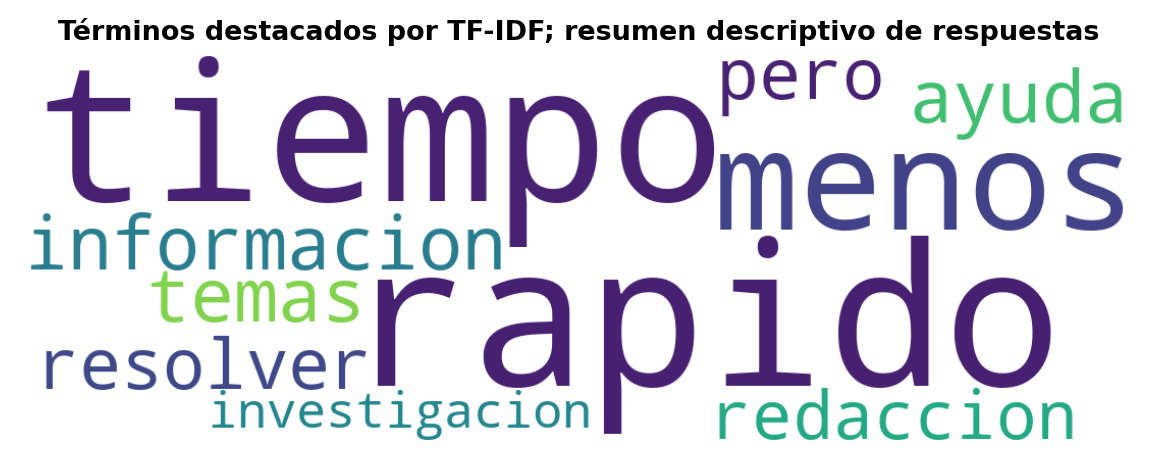

In [3]:
display(pd.DataFrame(r["polaridad_por_pregunta"]).T.round(3))
print("Cero significa balance o falta de vocabulario coincidente; no neutralidad demostrada.")
display(pd.Series(r["tfidf_top"], name="TF-IDF medio").to_frame())
display(Image(filename=str(OUT / "figuras" / "nlp.png")))

## 4. EDA y modalidades declaradas
Los descriptivos de entorno usan solo respuestas observadas. Guía, atajo e híbrido se distinguen de respuestas contextuales o insuficientes. Los porcentajes descriptivos mantienen como denominador las 24 respuestas.

,n,media,mediana,sd,min,max,q1,q3
horas_ia_dia,24.0,1.906,1.500,1.825,0.083,8.000,1.000,2.000
semestre_inicio,24.0,3.208,3.000,1.285,1.000,6.000,2.750,4.000
total_herramientas,24.0,1.750,2.000,0.847,1.000,4.000,1.000,2.000
score_beneficio_ia,24.0,0.136,0.154,0.143,-0.146,0.585,0.062,0.194
edad,19.0,22.158,22.000,1.302,21.000,25.000,21.000,23.000
traslado_min,19.0,70.526,60.000,75.699,10.000,360.000,35.000,75.000
score_bienestar,19.0,-0.002,0.000,0.134,-0.300,0.200,-0.100,0.100


,Respuestas
Híbrido,13
Guía,7
Atajo,2
Contextual,1
No clasificable,1


,Respuestas
No,11
Sí,8
Parcial / Depende,4
Indeciso,1


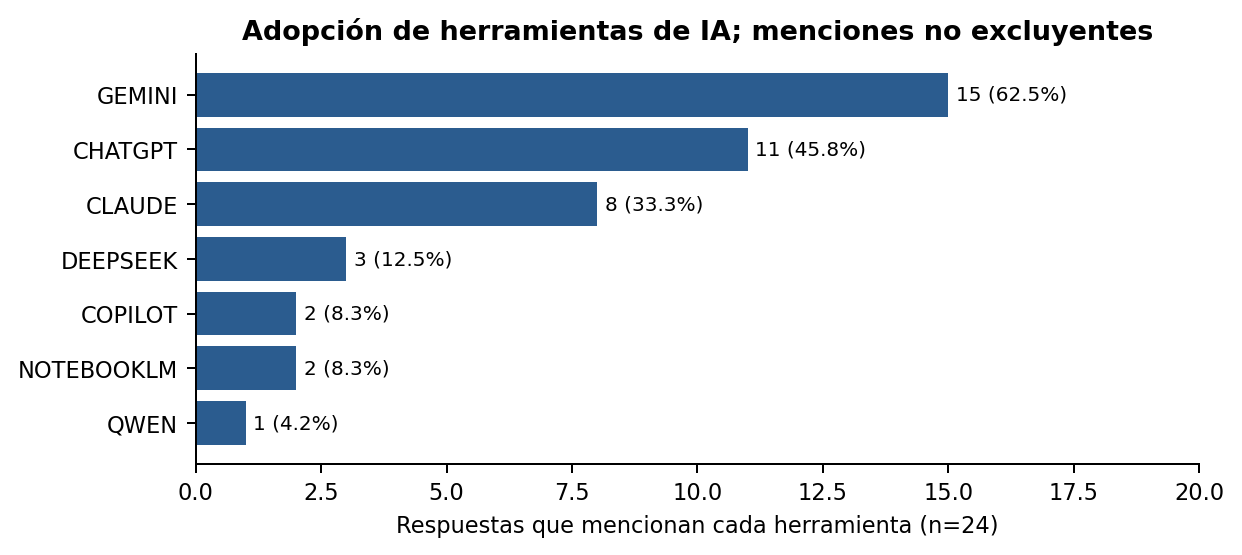

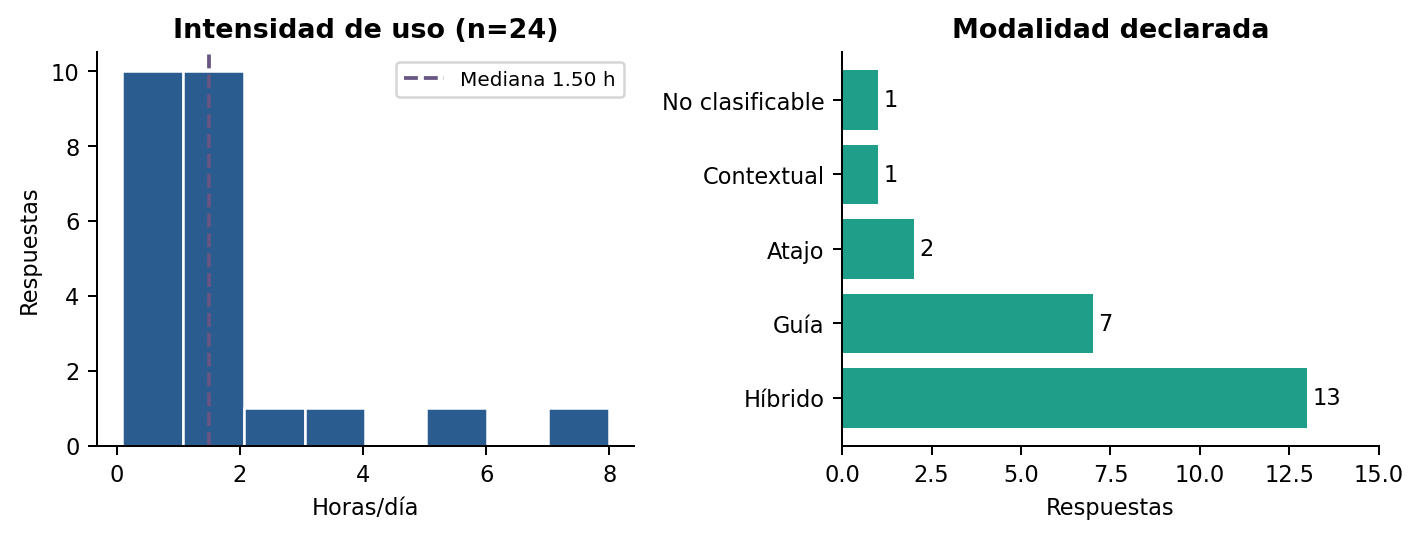

In [4]:
display(pd.DataFrame(r["descriptivos"]).T.round(3))
display(pd.Series(r["tipo_uso"], name="Respuestas").to_frame())
display(pd.Series(r["reemplazo"], name="Respuestas").to_frame())
display(Image(filename=str(OUT / "figuras" / "herramientas.png")))
display(Image(filename=str(OUT / "figuras" / "uso_modalidad.png")))

## 5. Cruce real y asociaciones
Se excluyen los casos sin encuesta de bienestar. Spearman es exploratorio: una asociación no prueba causalidad y un valor p grande no demuestra ausencia de relación. No se ajustó por comparaciones múltiples.

,n,rho,p
0,19,0.1375,0.5746


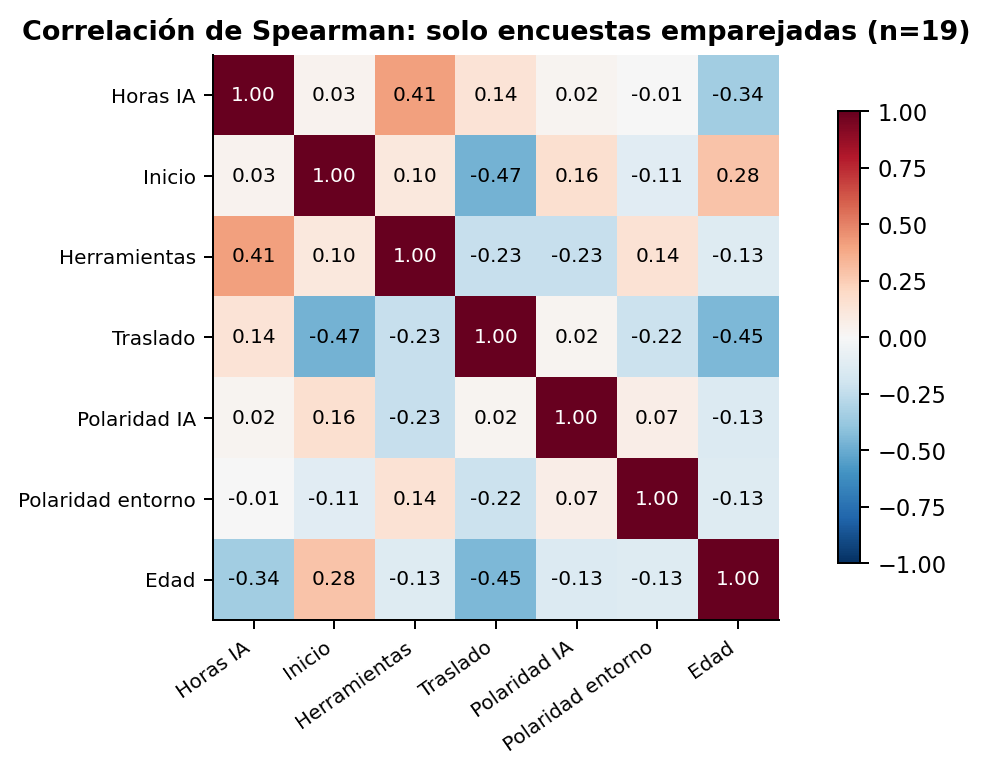

In [5]:
display(pd.DataFrame([r["correlacion_traslado_ia"]]).round(4))
display(Image(filename=str(OUT / "figuras" / "correlacion.png")))

## 6. Agrupación no supervisada y PCA
K-Means y clustering jerárquico se aplican a registros completos con bienestar observado. Se ensayan k=2..5 y se elige el mejor silhouette entre esos valores. Los grupos no son diagnósticos; se omiten perfiles con menos de tres integrantes.

,k,Silhouette
0,2,0.360289
1,3,0.134136
2,4,0.140553
3,5,0.139962


k seleccionado: 2 | Casos observados: 19
Varianza PCA acumulada: 49.46 %


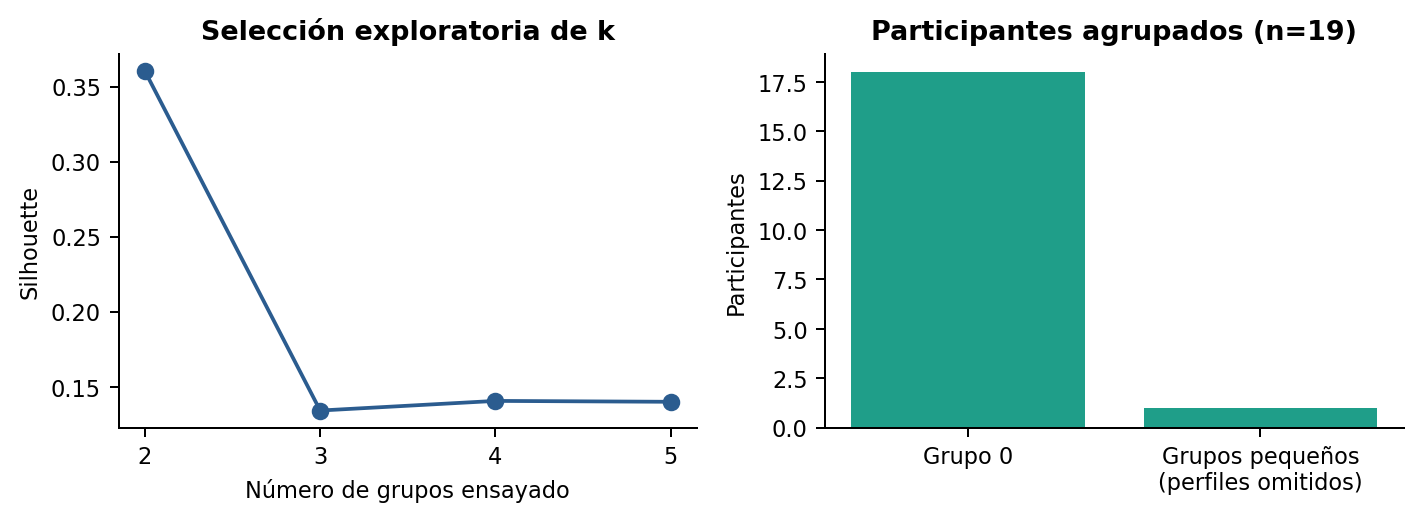

In [6]:
c = r["clusters"]
if c["estado"] == "ok":
    display(pd.DataFrame({"k": list(c["siluetas"]), "Silhouette": list(c["siluetas"].values())}))
    print("k seleccionado:", c["k"], "| Casos observados:", c["n"])
    print("Varianza PCA acumulada:", round(100 * sum(c["pca_varianza"]), 2), "%")
    display(Image(filename=str(OUT / "figuras" / "clusters.png")))
else:
    print("Muestra insuficiente para clustering.")

## 7. Clasificación supervisada sin fuga
Objetivo independiente del corpus predictor: modalidad mixta (1) frente a exclusiva como guía o atajo (0), según la pregunta específica de modalidad. Esa pregunta no entra en los predictores. Contextuales y no clasificables se excluyen.

Se reserva 25% para prueba. En cada fold de entrenamiento se ajustan escala, KNN, TF-IDF y PCA desde cero. La selección usa F1 medio de CV; se incluye la referencia de predecir siempre la clase mayoritaria. La prueba no se utiliza para seleccionar el modelo.

Entrenamiento: 16 | Prueba: 6 | Folds: 5
Respuestas excluidas por ambigüedad: 2


,modelo,cv_accuracy,cv_accuracy_sd,cv_f1,cv_f1_sd
0,Baseline (mayoría),0.567,0.149,0.713,0.132
1,Regresión logística,0.633,0.247,0.627,0.376
2,SVM,0.433,0.149,0.493,0.303
3,Random Forest,0.367,0.247,0.467,0.274
4,KNN,0.433,0.279,0.427,0.393


Candidato entre clasificadores: Regresión logística
Supera F1 del baseline en CV: False


,Candidato,Baseline
accuracy,0.833,0.667
precision,0.800,0.667
recall,1.000,1.000
f1,0.889,0.800


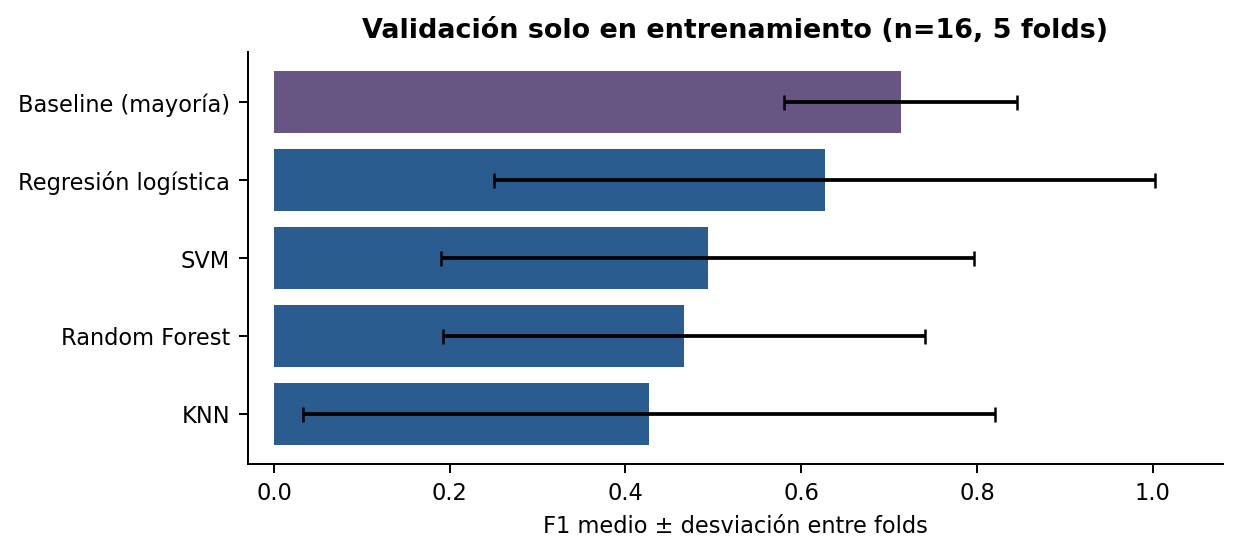

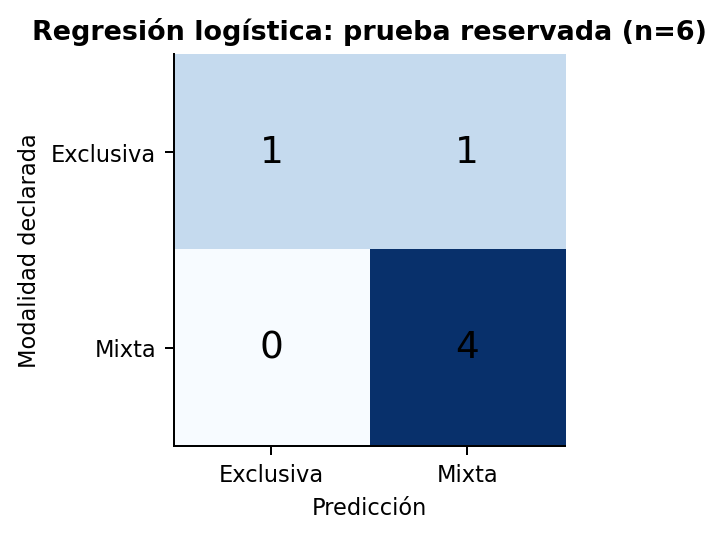

In [7]:
s = r["supervisado"]
if s["estado"] == "ok":
    print("Entrenamiento:", s["n_train"], "| Prueba:", s["n_test"], "| Folds:", s["n_folds"])
    print("Respuestas excluidas por ambigüedad:", s["n_excluidos"])
    display(pd.DataFrame(s["cv"]).drop(columns="fold_f1").round(3))
    print("Candidato entre clasificadores:", s["seleccionado"])
    print("Supera F1 del baseline en CV:", s["supera_baseline_cv"])
    display(pd.DataFrame({"Candidato": {k:v for k,v in s["test"].items() if k != "confusion"}, "Baseline": {k:v for k,v in s["baseline_test"].items() if k != "confusion"}}).round(3))
    display(Image(filename=str(OUT / "figuras" / "modelos_cv.png")))
    display(Image(filename=str(OUT / "figuras" / "confusion.png")))
else:
    print(s["motivo"])

## 8. Conclusiones de la ejecución
Los resultados se imprimen desde el mismo objeto que alimenta JSON, gráficas y PDF. No se fijan cifras manualmente en las conclusiones.

In [8]:
k = r["kpis"]
print(f"Modalidad híbrida explícita: {k["hibrido_pct"]:.1f}%.")
print(f"Guía o híbrida: {k["guia_hibrido_pct"]:.1f}%.")
print(f"Al menos dos herramientas: {k["multiherramienta_pct"]:.1f}%.")
print(f"Mediana de uso: {k["mediana_ia_h"]:.2f} horas/día.")
if s["estado"] == "ok":
    if not s["supera_baseline_cv"]:
        print("No se observó ventaja de F1 en CV frente al baseline; no se recomienda uso predictivo operativo.")
    print(f"Un acierto en prueba cambia accuracy en {s["test_sensible_pp"]:.1f} puntos porcentuales.")
print("La muestra no permite inferir causalidad, dependencia ni cambios objetivos de calificaciones.")
display(pd.Series(r["proveniencia"]["versiones"], name="Versión").to_frame())

Modalidad híbrida explícita: 54.2%.
Guía o híbrida: 83.3%.
Al menos dos herramientas: 54.2%.
Mediana de uso: 1.50 horas/día.
No se observó ventaja de F1 en CV frente al baseline; no se recomienda uso predictivo operativo.
Un acierto en prueba cambia accuracy en 16.7 puntos porcentuales.
La muestra no permite inferir causalidad, dependencia ni cambios objetivos de calificaciones.


,Versión
pandas,2.2.3
numpy,2.2.6
scikit-learn,1.6.1
scipy,1.15.3
matplotlib,3.10.7
